In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from datasets import load_dataset
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# 1. Načtení dat a nastavení datasetů
D1, y1 = make_blobs(n_samples=100, centers=2, cluster_std=1.0, random_state=7)
D2, y2 = make_blobs(n_samples=200, centers=4, cluster_std=1.0, random_state=7)
D3, y3 = make_moons(n_samples=200, noise=0.05, random_state=7)
D4, y4 = make_circles(n_samples=200, noise=0.03, factor=0.5, random_state=7)

datasets = [D1, D2, D3, D4]
targets = [y1, y2, y3, y4]
ks = [2, 4, 2, 2]
dataset_names = ["Dataset 1 (Blobs K=2)", "Dataset 2 (Blobs K=4)", "Dataset 3 (Moons K=2)", "Dataset 4 (Circles K=2)"]

def kmeans_numpy(X, K, tol=1e-6, max_iter=300, seed=None):
    if seed is not None:
        np.random.seed(seed)
    
    # Náhodný výběr K počátečních centroidů
    init_indices = np.random.choice(len(X), size=K, replace=False)
    centroids = X[init_indices].copy()
    
    j_history = []
    
    for _ in range(max_iter):
        dists = np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        
        # Přiřazení bodu k nejbližšímu centroidu
        labels = np.argmin(dists, axis=1)
        
        # Hodnota kritéria J = sum_j sum_i ||x_i^(j) - mu_j||^2
        min_dists = np.min(dists, axis=1)
        J = np.sum(min_dists)
        
        # Ověření, že J nikdy neroste (monotonie s malou tolerancí na zaokrouhlovací chyby)
        if len(j_history) > 0:
            assert J <= j_history[-1] + 1e-7, f"Chyba: Kritérium J vzrostlo z {j_history[-1]} na {J}"
            
        j_history.append(J)
        
        # Zastavovací podmínka: pokles J o méně než tol
        if len(j_history) > 1 and (j_history[-2] - J) < tol:
            break
            
        # Aktualizace centroidů (průměr přiřazených bodů)
        new_centroids = np.zeros_like(centroids)
        for k in range(K):
            mask = (labels == k)
            if np.any(mask):
                new_centroids[k] = X[mask].mean(axis=0)
            else:
                new_centroids[k] = centroids[k] # Ošetření prázdného shluku
        centroids = new_centroids
        
    return labels, centroids, j_history

def run_kmeans_10_times(X, K, n_runs=10):
    best_J = float('inf')
    best_result = None
    all_J = []
    
    for seed in range(n_runs):
        labels, centroids, j_history = kmeans_numpy(X, K, seed=seed)
        final_J = j_history[-1]
        all_J.append(final_J)
        
        if final_J < best_J:
            best_J = final_J
            best_result = (labels, centroids, j_history)
            
    return best_result, all_J

Dataset                   | Nejmenší J | Největší J | sklearn J  | ARI   
---------------------------------------------------------------------------
Dataset 1 (Blobs K=2)     | 194.63     | 194.63     | 194.63     | 1.00  
Dataset 2 (Blobs K=4)     | 384.85     | 4955.14    | 384.85     | 1.00  
Dataset 3 (Moons K=2)     | 80.39      | 80.39      | 80.39      | 0.24  
Dataset 4 (Circles K=2)   | 78.74      | 79.60      | 78.74      | -0.00 


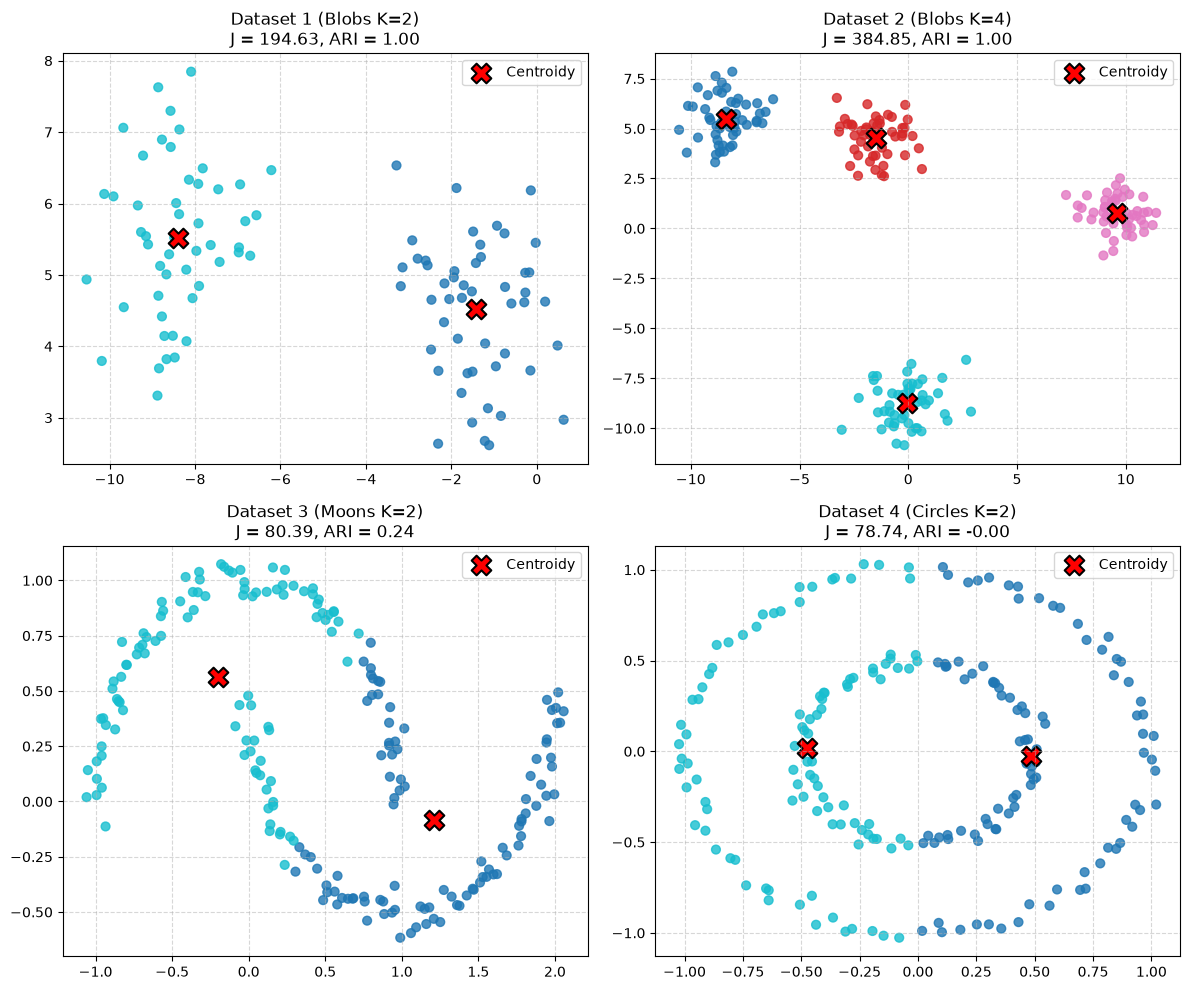

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

print(f"{'Dataset':<25} | {'Nejmenší J':<10} | {'Největší J':<10} | {'sklearn J':<10} | {'ARI':<6}")
print("-" * 75)

for idx, (X, y, K, name) in enumerate(zip(datasets, targets, ks, dataset_names)):
    (labels, centroids, j_history), all_J = run_kmeans_10_times(X, K)
    ari = adjusted_rand_score(y, labels)

    min_J = min(all_J)
    max_J = max(all_J)

    sk_kmeans = KMeans(n_clusters=K, random_state=7, n_init=10).fit(X)

    print(f"{name:<25} | {min_J:<10.2f} | {max_J:<10.2f} | {sk_kmeans.inertia_:<10.2f} | {ari:<6.2f}")

    ax = axes[idx]
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', alpha=0.8, s=40)
    ax.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200,
               edgecolor='black', linewidth=1.5, label='Centroidy')
    ax.set_title(f"{name}\nJ = {min_J:.2f}, ARI = {ari:.2f}")
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


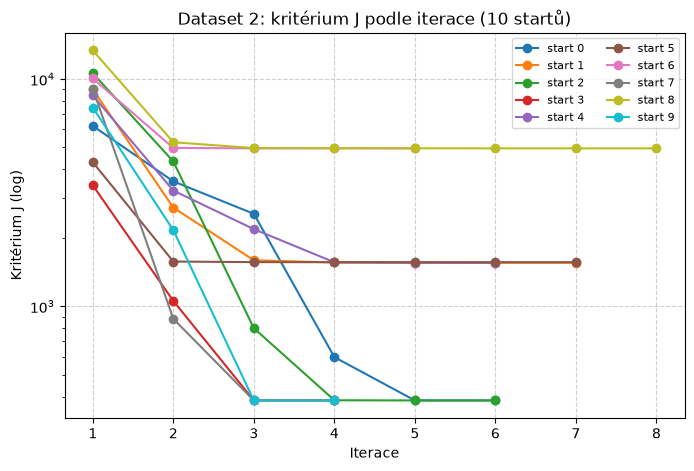

Dataset 2 - výsledky z 10 startů:
Nejmenší J: 384.85
Největší J: 4955.14


In [9]:
plt.figure(figsize=(8, 5))
all_J_d2 = []
for seed in range(10):
    _, _, j_hist = kmeans_numpy(D2, 4, seed=seed)  
    all_J_d2.append(j_hist[-1])
    plt.plot(range(1, len(j_hist) + 1), j_hist, marker='o', linewidth=1.5, label=f"start {seed}")
plt.yscale("log")
plt.title("Dataset 2: kritérium J podle iterace (10 startů)")
plt.xlabel("Iterace")
plt.ylabel("Kritérium J (log)")
plt.legend(ncol=2, fontsize=8)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Dataset 2 - výsledky z 10 startů:")
print(f"Nejmenší J: {min(all_J_d2):.2f}")
print(f"Největší J: {max(all_J_d2):.2f}")


In [10]:
W = np.load("som_W.npy").astype(np.float32)            # 1600 x 384
X = np.load("wiki_embeddings.npy").astype(np.float32)  # 241 787 x 384

wiki = load_dataset("wikimedia/wikipedia", "20231101.simple", split="train")
titles, texty = wiki["title"], wiki["text"]

# KROK 2: přiřazení článků k nejbližšímu neuronu
d2 = (X ** 2).sum(axis=1, keepdims=True) - 2 * X @ W.T + (W ** 2).sum(axis=1)   # ||x - w||^2
clanek_neuron = d2.argmin(axis=1)
vzdalenost = np.sqrt(np.maximum(d2.min(axis=1), 0))
pocty = np.bincount(clanek_neuron, minlength=len(W))

print(f"Průměrná vzdálenost článku k neuronu: {vzdalenost.mean():.2f}")
print(f"Počet neuronů bez článku: {(pocty == 0).sum()}")
print(f"Nejmenší počet článků na neuron: {pocty.min()}")
print(f"Mediánový počet článků na neuron: {np.median(pocty):.0f}")
print(f"Největší počet článků na neuron: {pocty.max()}")

# KROK 3: K-means (vlastní) na váhy neuronů, K = 8, 10 startů
(oblast_neuronu, centroids_W, _), J_W = run_kmeans_10_times(W, K=8, n_runs=10)
print(f"\nK-means na vahách: nejmenší J = {min(J_W):.2f}")

# Typická slova oblastí
tf = TfidfVectorizer(stop_words="english", min_df=20, max_df=0.2, sublinear_tf=True)
M = tf.fit_transform([f"{t}. {x[:600]}" for t, x in zip(titles, texty)])
slova = tf.get_feature_names_out()
vse = M.mean(axis=0).A1

oblast_clanku = oblast_neuronu[clanek_neuron]
for k in range(8):
    skore = M[oblast_clanku == k].mean(axis=0).A1 - vse
    print(k, slova[skore.argsort()[::-1][:6]])


Průměrná vzdálenost článku k neuronu: 0.80
Počet neuronů bez článku: 1
Nejmenší počet článků na neuron: 0
Mediánový počet článků na neuron: 140
Největší počet článků na neuron: 631

K-means na vahách: nejmenší J = 304.52
0 ['movies' 'movie' 'american' 'actors' 'directed' 'television']
1 ['album' 'song' 'songs' 'released' 'band' 'game']
2 ['commune' 'france' 'communes' 'department' 'region' 'north']
3 ['deaths' 'births' 'politician' 'died' 'politicians' 'president']
4 ['football' 'player' 'league' 'rowspan' 'played' 'team']
5 ['used' 'species' 'frog' 'called' 'usually' 'like']
6 ['county' 'states' 'united' 'cities' 'city' 'census']
7 ['municipality' 'district' 'municipalities' 'province' 'switzerland'
 'capital']


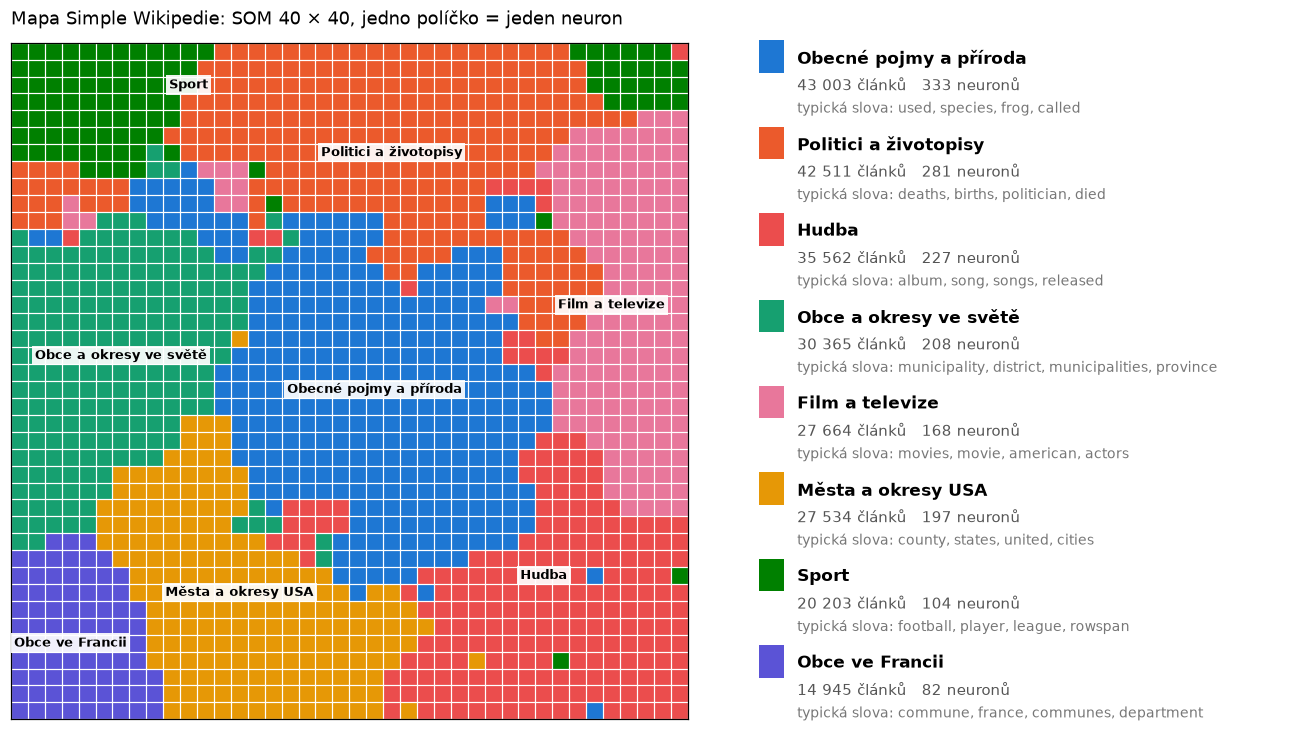

In [ ]:
OBLASTI_INFO = {
    0: {"name": "Film a televize"},          # movies, movie, american...
    1: {"name": "Hudba"},                    # album, song, released...
    2: {"name": "Obce ve Francii"},          # commune, france, communes...
    3: {"name": "Politici a životopisy"},    # deaths, births, politician...
    4: {"name": "Sport"},                    # football, player, league...
    5: {"name": "Obecné pojmy a příroda"},   # used, species, frog...
    6: {"name": "Města a okresy USA"},       # county, states, united...
    7: {"name": "Obce a okresy ve světě"},   # municipality, district...
}

stats = []
for k in range(8):
    mask_clanky = (oblast_clanku == k)
    n_art = int(mask_clanky.sum())
    n_neu = int((oblast_neuronu == k).sum())
    if n_art > 0:
        skore = M[mask_clanky].mean(axis=0).A1 - vse
        words_str = ", ".join(slova[skore.argsort()[::-1][:4]])
    else:
        words_str = ""
    stats.append({"k": k, "name": OBLASTI_INFO[k]["name"], "color": plt.cm.tab10(k),
                  "n_art": n_art, "n_neu": n_neu, "words": words_str})
stats_sorted = sorted(stats, key=lambda s: s["n_art"], reverse=True)

grid_mapa = oblast_neuronu.reshape(40, 40)

fig = plt.figure(figsize=(15, 8.5), dpi=110)
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.1)
ax_map = fig.add_subplot(gs[0])
ax_leg = fig.add_subplot(gs[1])

ax_map.imshow(grid_mapa, cmap="tab10", vmin=0, vmax=9)
ax_map.set_title("Mapa Simple Wikipedie: SOM 40 × 40, jedno políčko = jeden neuron", fontsize=12, loc="left", pad=12)
ax_map.set_xticks(np.arange(-0.5, 40), minor=True)
ax_map.set_yticks(np.arange(-0.5, 40), minor=True)
ax_map.grid(which="minor", color="white", linewidth=0.8)
ax_map.tick_params(which="both", length=0, labelbottom=False, labelleft=False)

# Popisek na políčku oblasti nejbližším k jejímu těžišti (leží vždy uvnitř oblasti)
for k in range(8):
    r_c, c_c = np.where(grid_mapa == k)
    if len(r_c) == 0:
        continue
    i = np.argmin((r_c - r_c.mean()) ** 2 + (c_c - c_c.mean()) ** 2)
    ax_map.text(c_c[i], r_c[i], OBLASTI_INFO[k]["name"], ha="center", va="center",
                bbox=dict(boxstyle="square,pad=0.25", facecolor="white", edgecolor="none", alpha=0.92),
                fontsize=8.5, fontweight="bold")

ax_leg.axis("off")
y_pos = 0.96
for item in stats_sorted:
    ax_leg.add_patch(mpatches.Rectangle((0.02, y_pos - 0.032), 0.045, 0.045,
                                        facecolor=item["color"], transform=ax_leg.transAxes))
    ax_leg.text(0.09, y_pos, item["name"], fontsize=11, fontweight="bold", transform=ax_leg.transAxes, va="top")
    ax_leg.text(0.09, y_pos - 0.038, f"{item['n_art']:,} článků   {item['n_neu']} neuronů".replace(",", " "),
                fontsize=9.5, color="#555555", transform=ax_leg.transAxes, va="top")
    ax_leg.text(0.09, y_pos - 0.072, f"typická slova: {item['words']}",
                fontsize=9, color="#777777", transform=ax_leg.transAxes, va="top")
    y_pos -= 0.12

fig.savefig("som_wiki_mapa.png", dpi=110, bbox_inches="tight")
plt.show()
